Let's make the map. 

In [9]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import matplotlib.cm as cm
import matplotlib.colors as colors
import imageio
import glob
import skgstat as skg
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit

In [ ]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())  

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-06-01        1981  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
4     POINT (135.33056 34.695)  1981  Seto Inlan

First, let's make the base map to show all of the sampling points in the SIS area. We will be using ```merged_gdf``` as the data source. The map will be color-coded based on the different water-masses indicated by the ```'division'``` column.

In [12]:
unique_points = summer_bottom_df['zettaicode'].drop_duplicates().tolist() # or .unique() can also work
print(unique_points)
print(f"Number of unique sampling points: {len(unique_points)}")

['00002811', '00002823', '00000272', '00000275', '00002725', '00036147', '00044533', '00044575', '00044578', '00044527', '00033182', '00035565', '00033237', '00035562', '00033224', '00035588', '00033241', '00033248', '00033204', '00035598', '00033277', '00034285', '00034310', '00033276', '00034332', '00034344', '00038667', '00035582', '00038671', '00035613', '00035626', '00035707', '00040632', '00003695', '00003698', '00034312', '00036103', '00038674', '00036164', '00044594', '00044529', '00044677', '00003089', '00040714', '00040715', '00036110', '00028169', '00035550', '00044531', '00037170', '00003086', '00044605', '00002750', '00002758', '00037179', '00035521', '00035522', '00034391', '00037213', '00035484', '00037181', '00037195', '00034423', '00037263', '00035512', '00038469', '00037238', '00044690', '00037250', '00037254', '00037298', '00038274', '00038647', '00038665', '00002848', '00028119', '00035486', '00038441', '00038495', '00002737', '00002744', '00044679', '00044680', '00

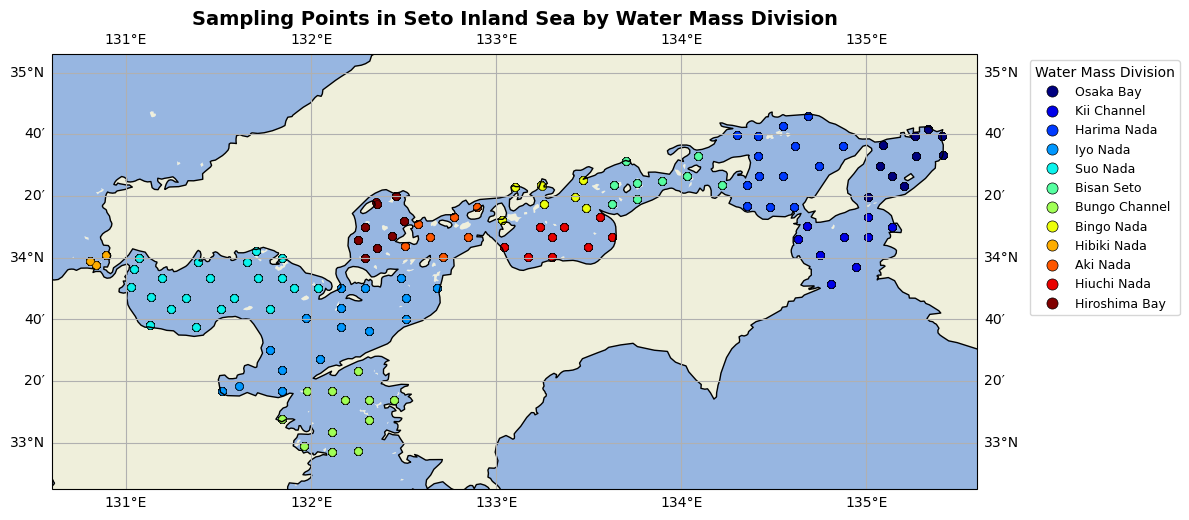

Total sampling points: 127
water masses: ['Osaka Bay', 'Kii Channel', 'Harima Nada', 'Iyo Nada', 'Suo Nada', 'Bisan Seto', 'Bungo Channel', 'Bingo Nada', 'Hibiki Nada', 'Aki Nada', 'Hiuchi Nada', 'Hiroshima Bay']


In [13]:
# Create base map with all sampling points colored by division (WITHOUT labels)
fig = plt.figure(figsize=(12, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# Get unique divisions and assign colors
divisions = merged_gdf['division'].unique()
colors_map = plt.cm.get_cmap('jet', len(divisions))
division_color_map = {div: colors_map(i) for i, div in enumerate(divisions)}

# Plot points colored by division
legend_elements = []
for division in divisions:
    div_data = merged_gdf[merged_gdf['division'] == division]
    ax.scatter(
        div_data.longitude, 
        div_data.latitude, 
        s=30,
        alpha=0.6,
        color=division_color_map[division],
        transform=ccrs.PlateCarree(),
        edgecolors='black',
        linewidth=0.3
    )
    # Create legend element with black edge
    from matplotlib.lines import Line2D
    legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                   markerfacecolor=division_color_map[division],
                                   markersize=8, markeredgecolor='black', 
                                   markeredgewidth=0.5, label=division))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05, 1), fontsize=9, title='Water Mass Division')

ax.set_title('Sampling Points in Seto Inland Sea by Water Mass Division', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Total sampling points: {len(unique_points)}")
print(f"water masses: {list(divisions)}")

Nice. Now let's make the frequency occurence map.

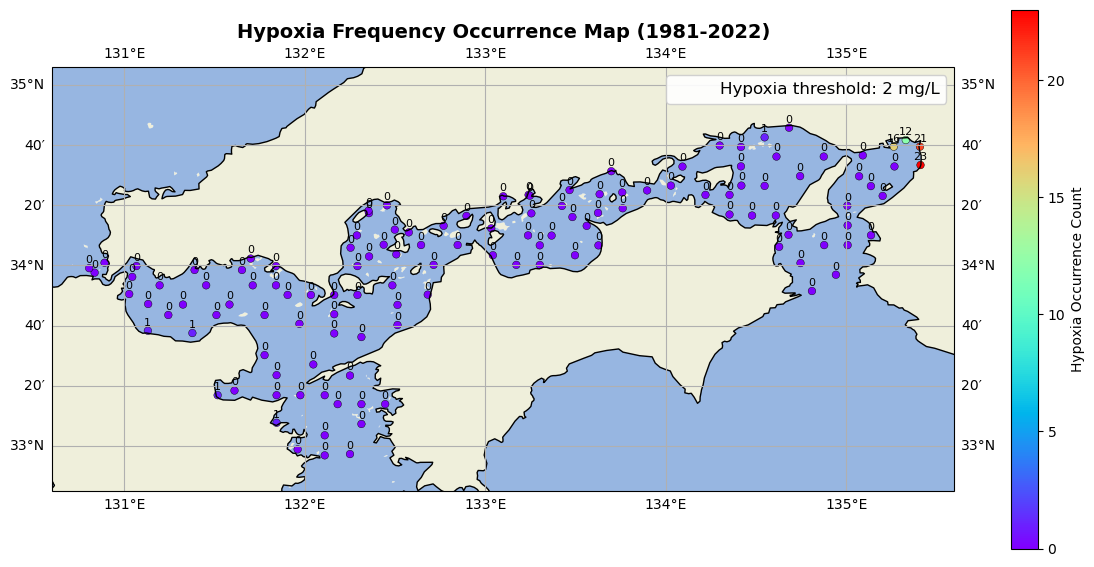

Total sampling points: 127
Max Occurrences: 23


In [20]:
# Define hypoxia threshold
hypoxia_threshold = 2
hypoxia_df = summer_bottom_df[summer_bottom_df['do_'] < hypoxia_threshold]

# Count occurrences for each unique 'zettaicode'
station_counts = hypoxia_df.groupby('zettaicode')['year'].nunique().reset_index(name='hypoxia_count')

# Merge with all stations to include those with 0 occurrences
all_stations = summer_bottom_df[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
plot_data = all_stations.merge(station_counts, on='zettaicode', how='left')
plot_data['hypoxia_count'] = plot_data['hypoxia_count'].fillna(0) # 0 occurrences for others

# === Plotting ===
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# Determine color scale components
# Blue to Red color scale
# Upper bound = ceil(max)
max_count = plot_data['hypoxia_count'].max()
vmax_val = np.ceil(max_count) if not pd.isna(max_count) and max_count > 0 else 5

# Plot points colored by hypoxia frequency
# Replaces the division loop with a single scatter plot mapped to the 'hypoxia_count' column
sc = ax.scatter(
    plot_data.geometry.x, 
    plot_data.geometry.y, 
    s=30,
    alpha=1,
    c=plot_data['hypoxia_count'],
    cmap='rainbow',
    vmin=0, 
    vmax=None,
    transform=ccrs.PlateCarree(),
    edgecolors='black',
    linewidth=0.3
)

# --- NEW: Add Count Labels above points ---
for idx, row in plot_data.iterrows():
    # Only label points that exist (though all should exist here)
    # Offset y by a small amount (e.g., 0.02 degrees) to place text above the dot
    x, y = row.geometry.x, row.geometry.y
    count = int(row['hypoxia_count'])
    
    ax.text(x, y + 0.02, str(count),
            fontsize=8, 
            ha='center', 
            va='bottom', 
            fontweight='normal',
            color='black',
            transform=ccrs.PlateCarree())

# --- NEW: Add Legend for Threshold ---
# Create an invisible plot element just to hold the label in the legend
ax.plot([], [], ' ', label=f"Hypoxia threshold: {hypoxia_threshold} mg/L")
ax.legend(loc='upper right', framealpha=0.9, fontsize=12)

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.05)
cbar.set_label('Hypoxia Occurrence Count')
ax.set_title('Hypoxia Frequency Occurrence Map (1981-2022)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Total sampling points: {len(plot_data)}")
print(f"Max Occurrences: {int(vmax_val)}")

This map only shows stations in inner Osaka Bay has the highest hypoxia frequency across all years. But this will depend on the threshold I use.